In [2]:
# %pip install -q pandas matplotlib seaborn scikit-learn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

In [3]:
CSV_PATH = "cyber_threats_dataset.csv"

df = pd.read_csv(CSV_PATH)
df.info()
df.describe(include="all")

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Timestamp               200 non-null    str  
 1   Protocol                200 non-null    str  
 2   Flag                    200 non-null    str  
 3   Packet                  200 non-null    str  
 4   Sender ID               200 non-null    int64
 5   Receiver ID             200 non-null    int64
 6   Source IP Address       200 non-null    str  
 7   Source Country          200 non-null    str  
 8   Destination IP Address  200 non-null    str  
 9   Destination Country     200 non-null    str  
 10  Source Port             200 non-null    int64
 11  Destination Port        200 non-null    int64
 12  Packet Size             200 non-null    int64
 13  Target Variable         200 non-null    str  
dtypes: int64(5), str(9)
memory usage: 22.0 KB


,Timestamp,Protocol,Flag,Packet,Sender ID,Receiver ID,Source IP Address,Source Country,Destination IP Address,Destination Country,Source Port,Destination Port,Packet Size,Target Variable
count,200,200,200,200,200.00000,200.000000,200,200,200,200,200.000000,200.000000,200.00000,200
unique,200,2,4,6,NaN,NaN,200,20,200,20,NaN,NaN,NaN,17
top,2025-01-01T00:00:00+00:00,TCP,SYN,ICMP,NaN,NaN,116.67.62.157,United States,43.189.230.39,Japan,NaN,NaN,NaN,DoS
freq,1,107,55,40,NaN,NaN,1,17,1,16,NaN,NaN,NaN,20
mean,NaN,NaN,NaN,NaN,486.69500,510.855000,NaN,NaN,NaN,NaN,31699.100000,34640.455000,2170.72500,NaN
std,NaN,NaN,NaN,NaN,281.84288,286.479715,NaN,NaN,NaN,NaN,18466.885671,18322.400492,1165.79527,NaN
min,NaN,NaN,NaN,NaN,6.00000,7.000000,NaN,NaN,NaN,NaN,264.000000,732.000000,95.00000,NaN
25%,NaN,NaN,NaN,NaN,254.75000,253.000000,NaN,NaN,NaN,NaN,15883.000000,19230.500000,1161.75000,NaN
50%,NaN,NaN,NaN,NaN,462.00000,527.000000,NaN,NaN,NaN,NaN,31058.000000,34549.000000,2262.50000,NaN
75%,NaN,NaN,NaN,NaN,725.50000,727.500000,NaN,NaN,NaN,NaN,46172.750000,50150.000000,3121.25000,NaN


In [19]:
df.head()
print("Кількість рядків у датасеті:", len(df))

Кількість рядків у датасеті: 200


In [20]:
threat_counts = df["Target Variable"].value_counts()
print(threat_counts)

threat_df = pd.DataFrame({"Threat Type": threat_counts.index, "Count": threat_counts.values})
threat_df

Target Variable
DoS                    20
SQL Injection          19
Trojan                 18
Brute Force            17
Insider Threat         16
Phishing               15
DDoS                   12
Spyware                12
Ransomware             12
XSS                    10
Zero-day Exploit        9
Port Scanning           8
Malware                 8
Botnet Activity         6
Man-in-the-Middle       6
CSRF                    6
Credential Stuffing     6
Name: count, dtype: int64


,Threat Type,Count
0,DoS,20
1,SQL Injection,19
2,Trojan,18
3,Brute Force,17
4,Insider Threat,16
5,Phishing,15
6,DDoS,12
7,Spyware,12
8,Ransomware,12
9,XSS,10


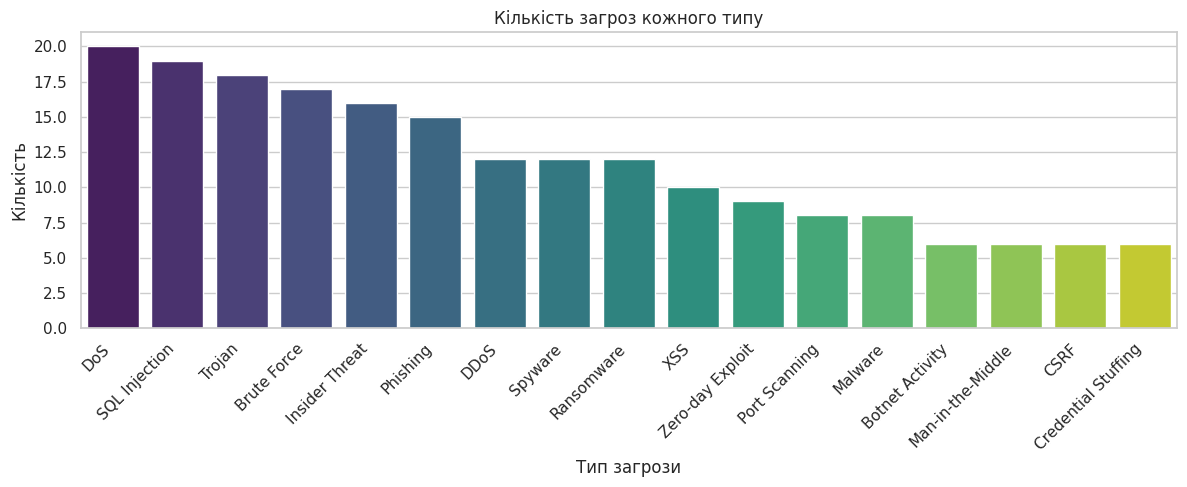

In [21]:
plt.figure(figsize=(12, 5))
sns.barplot(data=threat_df, x="Threat Type", y="Count", hue="Threat Type", palette="viridis", legend=False)
plt.xticks(rotation=45, ha="right")
plt.xlabel("Тип загрози")
plt.ylabel("Кількість")
plt.title("Кількість загроз кожного типу")
plt.tight_layout()
plt.show()

In [22]:
HIGH = {
    "Ransomware",
    "DDoS",
    "SQL Injection",
    "Zero-day Exploit",
    "Malware",
    "Trojan",
}
MEDIUM = {
    "DoS",
    "Phishing",
    "Man-in-the-Middle",
    "Credential Stuffing",
    "Port Scanning",
    "Botnet Activity",
    "Spyware",
}


def map_danger(threat: str) -> str:
    if threat in HIGH:
        return "High"
    if threat in MEDIUM:
        return "Medium"
    return "Low"


df = df.copy()
df["Danger Level"] = df["Target Variable"].map(map_danger)

danger_ip_counts = df.groupby(["Danger Level", "Source IP Address"]).size()
print(danger_ip_counts.head(20))

Danger Level  Source IP Address
High          102.26.137.111       1
              109.234.9.210        1
              115.91.224.136       1
              116.67.62.157        1
              120.8.204.180        1
              121.53.139.193       1
              125.209.3.87         1
              126.66.207.154       1
              130.231.151.111      1
              131.227.190.82       1
              134.254.93.181       1
              134.31.60.186        1
              138.193.28.31        1
              14.242.206.188       1
              144.24.43.85         1
              146.38.235.173       1
              148.2.223.89         1
              149.239.135.165      1
              149.89.189.222       1
              155.17.77.5          1
dtype: int64


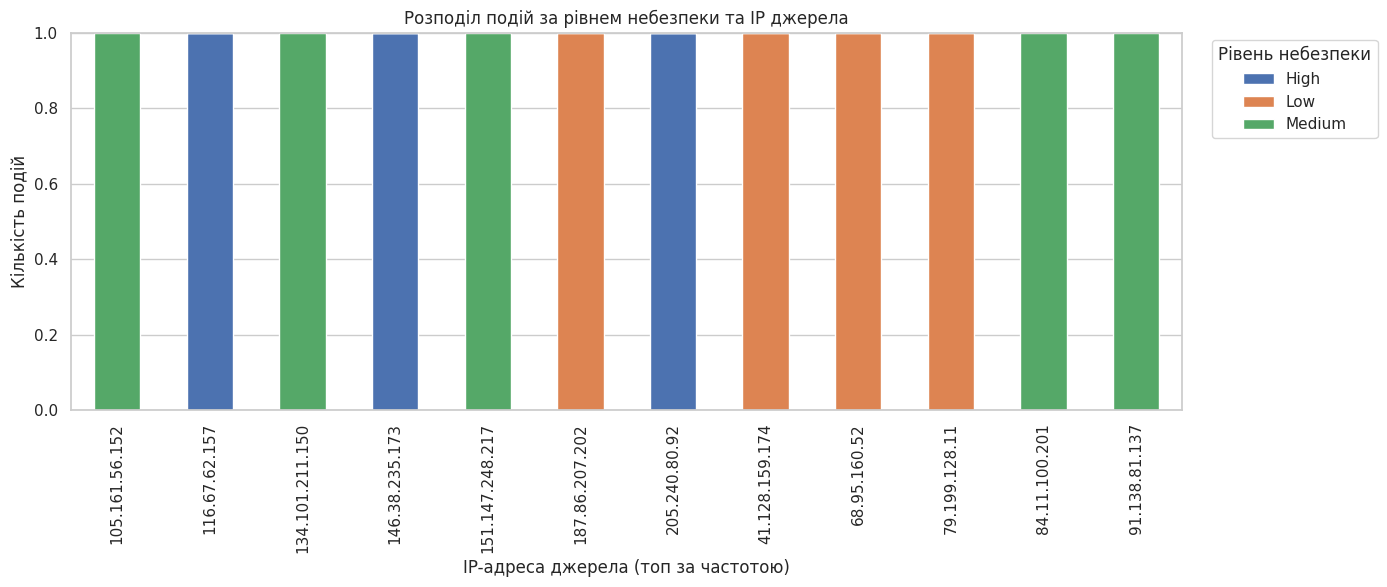

In [23]:
plot_df = danger_ip_counts.unstack(fill_value=0)
top_ips = df["Source IP Address"].value_counts().head(12).index
plot_df = plot_df[[c for c in plot_df.columns if c in top_ips]]

plot_df.T.plot(kind="bar", stacked=True, figsize=(14, 6))
plt.xlabel("IP-адреса джерела (топ за частотою)")
plt.ylabel("Кількість подій")
plt.title("Розподіл подій за рівнем небезпеки та IP джерела")
plt.legend(title="Рівень небезпеки", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [24]:
print("Кількість унікальних Source IP:", df["Source IP Address"].nunique())
print("Кількість унікальних Destination IP:", df["Destination IP Address"].nunique())

df["Source IP Address"].unique()[:10], df["Destination IP Address"].unique()[:10]

Кількість унікальних Source IP: 200
Кількість унікальних Destination IP: 200


(<StringArray>
 [  '116.67.62.157',  '105.161.56.152',   '84.11.100.201',  '146.38.235.173',
   '41.128.159.174', '151.147.248.217',   '205.240.80.92',    '68.95.160.52',
    '91.138.81.137',   '79.199.128.11']
 Length: 10, dtype: str,
 <StringArray>
 [  '43.189.230.39',  '178.110.136.77',  '25.167.236.194',    '148.82.31.82',
     '90.54.55.114',  '210.160.17.248',   '150.99.120.57',   '41.226.52.154',
  '208.222.197.119',  '125.50.112.109']
 Length: 10, dtype: str)

In [25]:
high_threats = df[df["Danger Level"] == "High"]
high_threats.head()

,Timestamp,Protocol,Flag,Packet,Sender ID,Receiver ID,Source IP Address,Source Country,Destination IP Address,Destination Country,Source Port,Destination Port,Packet Size,Target Variable,Danger Level,Source IP kind,Destination IP kind,Threat scope
0,2025-01-01T00:00:00+00:00,TCP,ACK,SMTP,178,423,116.67.62.157,Brazil,43.189.230.39,Germany,47093,22375,1132,DDoS,High,public,public,external
3,2025-01-08T04:13:15.964824+00:00,UDP,RST,HTTP,437,326,146.38.235.173,Japan,148.82.31.82,India,1060,33059,1937,Ransomware,High,public,public,external
6,2025-01-15T08:26:31.929648+00:00,UDP,SYN,HTTP,509,349,205.240.80.92,South Africa,150.99.120.57,Germany,15665,17090,3730,Ransomware,High,public,public,external
12,2025-01-29T16:53:03.859297+00:00,UDP,FIN,HTTP,543,34,60.97.23.1,Netherlands,150.171.33.211,Brazil,12598,44902,2915,DDoS,High,public,public,external
15,2025-02-05T21:06:19.824121+00:00,UDP,SYN,FTP,942,769,77.112.129.234,Singapore,80.78.204.44,Ukraine,36496,49928,364,Ransomware,High,public,public,external


Protocol
TCP    107
UDP     93
Name: count, dtype: int64


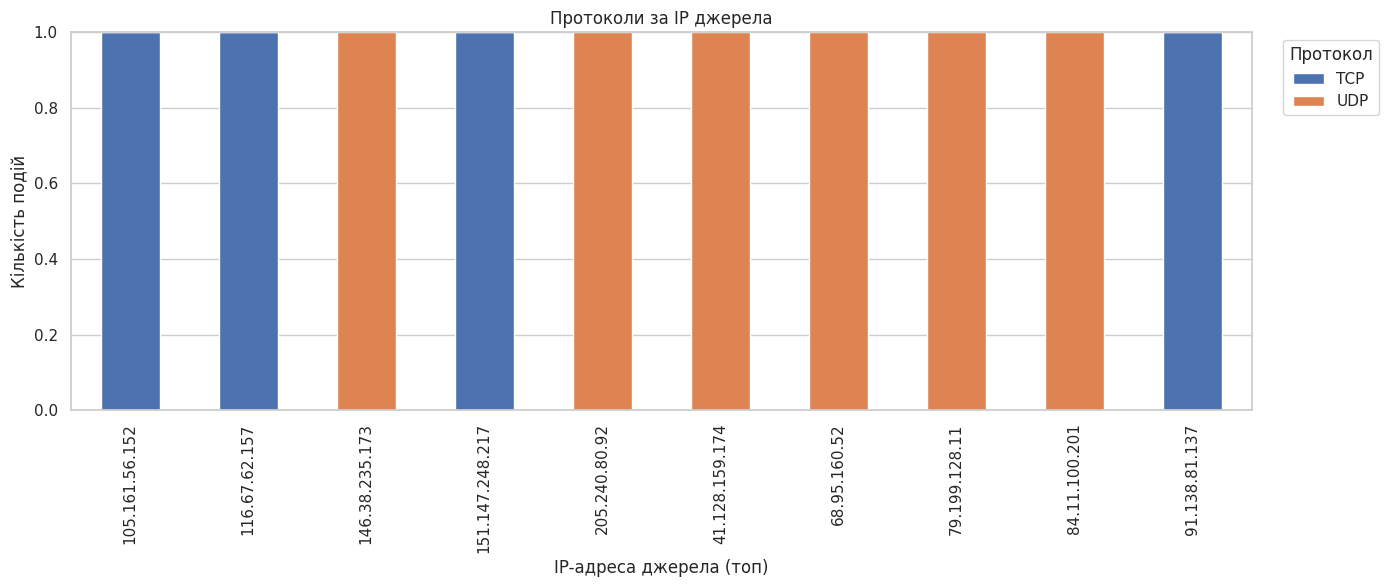

In [26]:
protocol_counts = df["Protocol"].value_counts()
print(protocol_counts)

protocol_ip = df.groupby(["Protocol", "Source IP Address"]).size().unstack(fill_value=0)
top_ips_p = df["Source IP Address"].value_counts().head(10).index
protocol_ip = protocol_ip[[c for c in protocol_ip.columns if c in top_ips_p]]

protocol_ip.T.plot(kind="bar", stacked=True, figsize=(14, 6))
plt.xlabel("IP-адреса джерела (топ)")
plt.ylabel("Кількість подій")
plt.title("Протоколи за IP джерела")
plt.legend(title="Протокол", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [27]:
df["Packet Size"].describe()

count     200.00000
mean     2170.72500
std      1165.79527
min        95.00000
25%      1161.75000
50%      2262.50000
75%      3121.25000
max      4072.00000
Name: Packet Size, dtype: float64

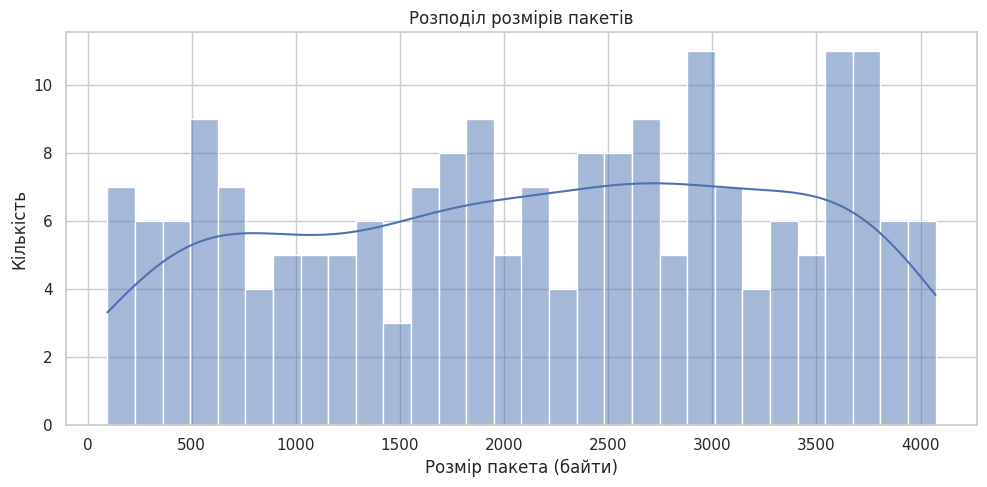

In [28]:
plt.figure(figsize=(10, 5))
sns.histplot(df["Packet Size"], bins=30, kde=True)
plt.xlabel("Розмір пакета (байти)")
plt.ylabel("Кількість")
plt.title("Розподіл розмірів пакетів")
plt.tight_layout()
plt.show()

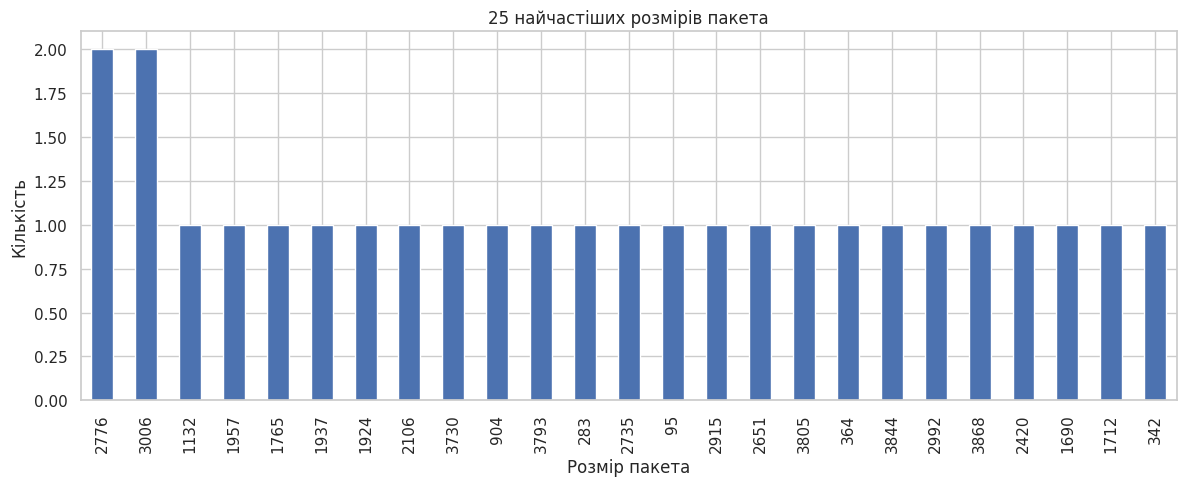

In [29]:
packet_size_counts = df["Packet Size"].value_counts().head(25)
packet_size_counts.plot(kind="bar", figsize=(12, 5))
plt.xlabel("Розмір пакета")
plt.ylabel("Кількість")
plt.title("25 найчастіших розмірів пакета")
plt.tight_layout()
plt.show()

In [30]:
import ipaddress


def ip_kind(value: str) -> str:
    addr = ipaddress.ip_address(value)
    if addr.is_private:
        return "private"
    return "public"


df["Source IP kind"] = df["Source IP Address"].map(ip_kind)
df["Destination IP kind"] = df["Destination IP Address"].map(ip_kind)

df[["Source IP Address", "Source IP kind", "Destination IP Address", "Destination IP kind"]].head(10)

,Source IP Address,Source IP kind,Destination IP Address,Destination IP kind
0,116.67.62.157,public,43.189.230.39,public
1,105.161.56.152,public,178.110.136.77,public
2,84.11.100.201,public,25.167.236.194,public
3,146.38.235.173,public,148.82.31.82,public
4,41.128.159.174,public,90.54.55.114,public
5,151.147.248.217,public,210.160.17.248,public
6,205.240.80.92,public,150.99.120.57,public
7,68.95.160.52,public,41.226.52.154,public
8,91.138.81.137,public,208.222.197.119,public
9,79.199.128.11,public,125.50.112.109,public


In [31]:
def threat_scope(row) -> str:
    if row["Source IP kind"] == "private" and row["Destination IP kind"] == "private":
        return "internal"
    return "external"

df["Threat scope"] = df.apply(threat_scope, axis=1)
scope_counts = df["Threat scope"].value_counts()
scope_counts

Threat scope
external    200
Name: count, dtype: int64

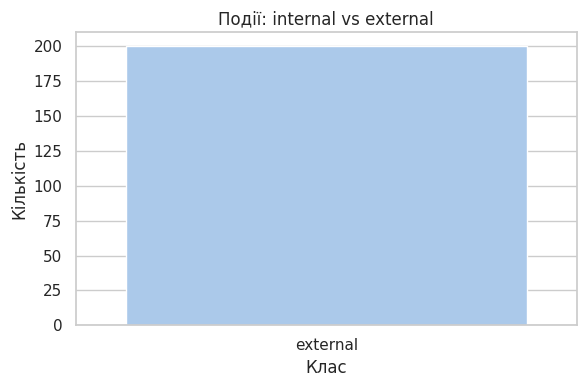

In [32]:
plt.figure(figsize=(6, 4))
sns.barplot(x=scope_counts.index, y=scope_counts.values, hue=scope_counts.index, palette="pastel", legend=False)
plt.title("Події: internal vs external")
plt.xlabel("Клас")
plt.ylabel("Кількість")
plt.tight_layout()
plt.show()

In [34]:
df["event_time"] = pd.to_datetime(df["Timestamp"], utc=True, format="ISO8601")
df["hour"] = df["event_time"].dt.hour

hourly = df["hour"].value_counts().sort_index()
peak_hour = hourly.idxmax()
print("Найбільш активна година (UTC):", peak_hour)
hourly

Найбільш активна година (UTC): 0


hour
0     9
1     8
2     8
3     9
4     8
5     8
6     9
7     8
8     8
9     8
10    9
11    8
12    8
13    9
14    8
15    8
16    8
17    9
18    8
19    8
20    9
21    8
22    8
23    9
Name: count, dtype: int64

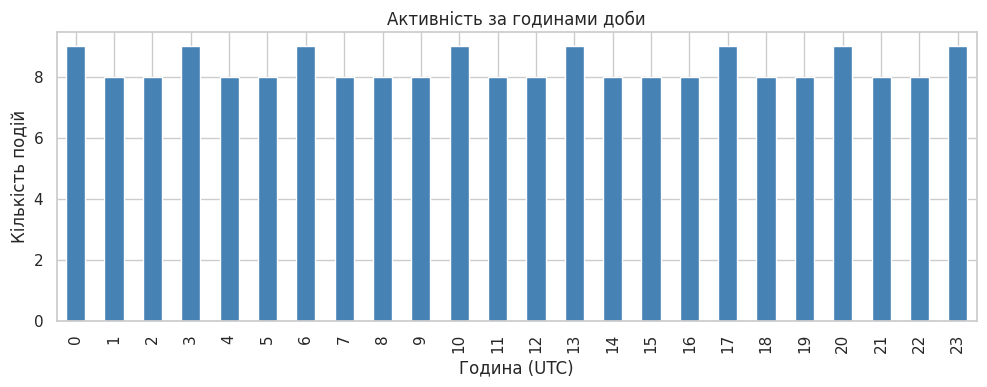

In [35]:
plt.figure(figsize=(10, 4))
hourly.plot(kind="bar", color="steelblue")
plt.xlabel("Година (UTC)")
plt.ylabel("Кількість подій")
plt.title("Активність за годинами доби")
plt.tight_layout()
plt.show()

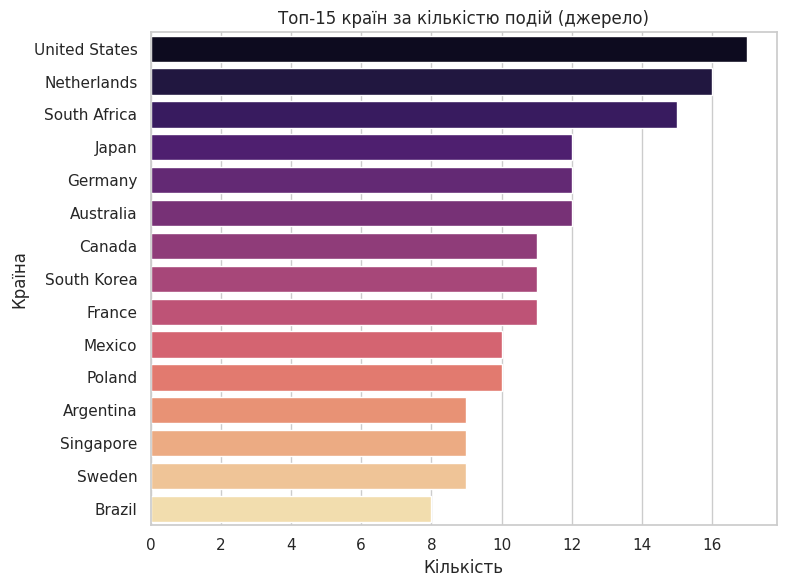

In [36]:
country_counts = df["Source Country"].value_counts().head(15)
plt.figure(figsize=(8, 6))
sns.barplot(x=country_counts.values, y=country_counts.index, hue=country_counts.index, palette="magma", legend=False)
plt.title("Топ-15 країн за кількістю подій (джерело)")
plt.xlabel("Кількість")
plt.ylabel("Країна")
plt.tight_layout()
plt.show()

In [37]:
ip_threat_diversity = (
    df.groupby("Source IP Address")["Target Variable"].nunique().sort_values(ascending=False)
)
ip_event_counts = df["Source IP Address"].value_counts()

top_div = ip_threat_diversity.head(10)
top_freq = ip_event_counts.head(10)

print(top_div.to_frame("unique_threat_types"))
print(top_freq.to_frame("events"))

                   unique_threat_types
Source IP Address                     
100.223.217.190                      1
101.126.89.127                       1
102.26.137.111                       1
105.161.56.152                       1
108.39.240.94                        1
109.234.9.210                        1
11.219.236.178                       1
115.91.224.136                       1
116.67.62.157                        1
118.161.254.192                      1
                   events
Source IP Address        
116.67.62.157           1
105.161.56.152          1
84.11.100.201           1
146.38.235.173          1
41.128.159.174          1
151.147.248.217         1
205.240.80.92           1
68.95.160.52            1
91.138.81.137           1
79.199.128.11           1


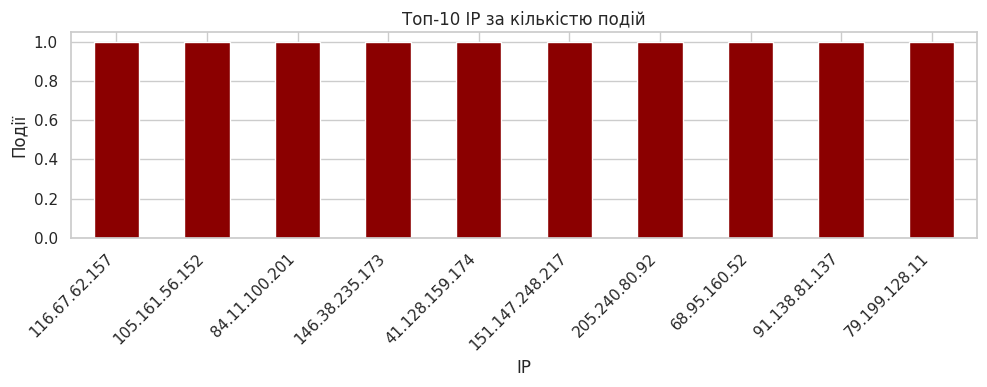

In [40]:
plt.figure(figsize=(10, 4))
top_freq.plot(kind="bar", color="darkred")
plt.title("Топ-10 IP за кількістю подій")
plt.xlabel("IP")
plt.ylabel("Події")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()